# Day 08. Exercise 02
# Multiclass classification. One-hot encoding. Random forest

## 0. Imports

In [1491]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.metrics import accuracy_score

import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression

from sklearn.svm import SVC
from sklearn.multiclass import OneVsRestClassifier

from sklearn.tree import DecisionTreeClassifier

from sklearn.ensemble import RandomForestClassifier

## 1. Preprocessing

1. Read the file [`checker-submits.csv`](https://drive.google.com/file/d/14voc4fNJZiLEFaZyd8nEG-lQt5JjatYw/view?usp=sharing).
2. Create a dataframe `df` with the columns: `uid`, `labname`, `numTrials`, `hour`, `dayofweek` where `hour` is extracted from the `timestamp` as well as the `dayofweek` (`0` is Monday, `6` is Sunday). We will try to predict the day of the week having data about which user made a commit for which lab at which hour and which try it was.
3. Using `OneHotEncoder()` transform your categorical features, delete from the dataframe the initial columns.
4. Use `StandardScaler()` and scale your continuous features.
5. Save the dataframe as `dayofweek.csv`.
6. Before trying out different algorithms, find out the accuracy of the naive algorithms – the one that predicts everything as the most popular class.

In [1492]:
df_raw = pd.read_csv('../data/checker_submits.csv', parse_dates=['timestamp'])

In [1493]:
df = pd.DataFrame()

df['uid'] = df_raw['uid']
df['labname'] = df_raw['labname']
df['numTrials'] = df_raw['numTrials']
df['hour'] = df_raw['timestamp'].dt.hour
df['dayofweek'] = df_raw['timestamp'].dt.dayofweek

### categorical features transform

In [1494]:
ohe = OneHotEncoder(sparse_output=False)
cat_features = ['uid', 'labname']
encoded_cats = ohe.fit_transform(df[cat_features])

In [1495]:
encoded_df = pd.DataFrame(encoded_cats, columns=ohe.get_feature_names_out(cat_features))

### scale features

In [1496]:
scaler = StandardScaler()
cont_features = ['numTrials', 'hour']
scaled_cont = scaler.fit_transform(df[cont_features])


In [1497]:
scaled_df = pd.DataFrame(scaled_cont, columns=cont_features)

### final concat and saving

In [1498]:
df_final = pd.concat([encoded_df, scaled_df, df['dayofweek']], axis=1)
df_final.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1686 entries, 0 to 1685
Data columns (total 44 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   uid_user_0        1686 non-null   float64
 1   uid_user_1        1686 non-null   float64
 2   uid_user_10       1686 non-null   float64
 3   uid_user_11       1686 non-null   float64
 4   uid_user_12       1686 non-null   float64
 5   uid_user_13       1686 non-null   float64
 6   uid_user_14       1686 non-null   float64
 7   uid_user_15       1686 non-null   float64
 8   uid_user_16       1686 non-null   float64
 9   uid_user_17       1686 non-null   float64
 10  uid_user_18       1686 non-null   float64
 11  uid_user_19       1686 non-null   float64
 12  uid_user_2        1686 non-null   float64
 13  uid_user_20       1686 non-null   float64
 14  uid_user_21       1686 non-null   float64
 15  uid_user_22       1686 non-null   float64
 16  uid_user_23       1686 non-null   float64


In [1499]:
df_final.to_csv('../data/dayofweek.csv', index=False)

### naive accuracy

In [1500]:
most_popular_day = df['dayofweek'].value_counts().idxmax()

In [1501]:
naive_preds = [most_popular_day] * len(df)
naive_acc = accuracy_score(df['dayofweek'], naive_preds)
naive_acc

0.23487544483985764

## 2. Algorithms

### a. Logreg

1. Train logistic regression, for the baseline model use `random_state=21`, `fit_intercept=False`. 
2. Calculate the accuracy.
3. Write a function that draws the plot (`barh`) taking coefficients of any trained models, names of the features and the number of `top-n` most important features to display.
4. Draw a plot (`barh`) for the baseline model with top-10 most important features (absolute value) for the trained model.
5. Remember that it is a multiclass classification and `coef_` returns a matrix, to calculate importance for a feature you need to sum all the individual feature importances for all the target values.

In [1502]:
df = pd.read_csv('../data/dayofweek.csv')
X = df.drop('dayofweek', axis=1)
y = df['dayofweek']

### train the logistic regression

In [1503]:
base_logreg = LogisticRegression(
    random_state=21, 
    fit_intercept=False, 
    solver='liblinear', 
    C=10, 
    max_iter=1000
)

logreg = OneVsRestClassifier(base_logreg)
logreg.fit(X, y)

,"estimator estimator: estimator objectA regressor or a classifier that implements :term:`fit`.When a classifier is passed, :term:`decision_function` will be usedin priority and it will fallback to :term:`predict_proba` if it is notavailable.When a regressor is passed, :term:`predict` is used.",LogisticRegre...r='liblinear')
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation: the `n_classes`one-vs-rest problems are computed in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details... versionchanged:: 0.20 `n_jobs` default changed from 1 to None",None
,"verbose verbose: int, default=0The verbosity level, if non zero, progress messages are printed.Below 50, the output is sent to stderr. Otherwise, the output is sentto stdout. The frequency of the messages increases with the verbositylevel, reporting all iterations at 10. See :class:`joblib.Parallel` formore details... versionadded:: 1.1",0
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add a L2 penalty term and it is the default choice;- `'l1'`: add a L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'` and `l1_ratio` set to any float between 0 and 1 for `'penalty='elasticnet'`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",10
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation `) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",False
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=

### accuracy

In [1504]:
y_pred = logreg.predict(X)
acc = accuracy_score(y, y_pred)
acc

0.6482799525504152

### plot drawing

In [1505]:
def plot_feature_importance(model, feature_names, n_top):
    all_coefs = np.array([est.coef_[0] for est in model.estimators_])
    # sum for 7 classes
    importances = np.sum(np.abs(all_coefs), axis=0)

    # df for sorting
    feat_importance = pd.DataFrame({'feature': feature_names, 'importance': importances})
    feat_importance = feat_importance.sort_values('importance', ascending=False).head(n_top)

    plt.figure(figsize=(10, 6))
    plt.barh(feat_importance['feature'], feat_importance['importance'], color='skyblue')

    # invert for put the most important on high
    plt.gca().invert_yaxis()
    plt.xticks(rotation=90)
    plt.title(f"Top {n_top} Most Important Features")
    plt.xlabel("Sum of absolute coeffs")
    plt.show()

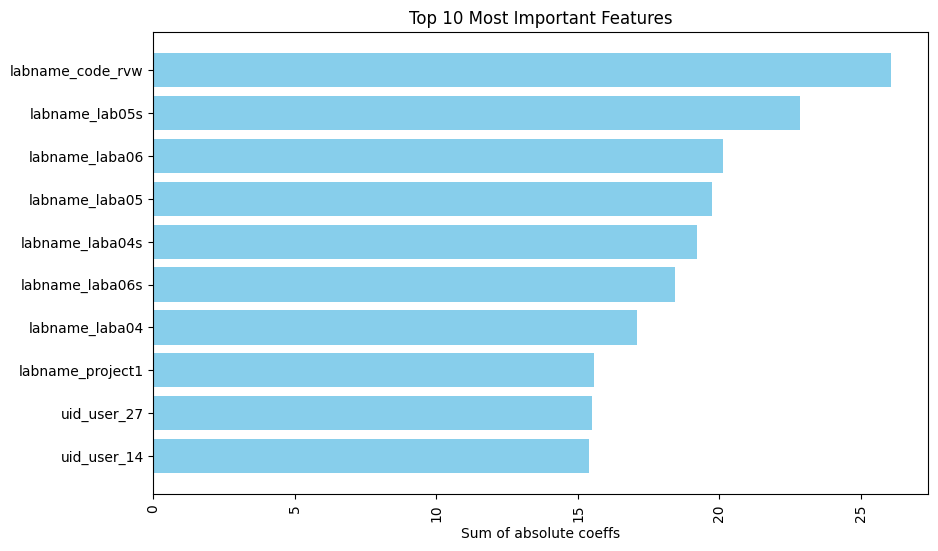

In [1506]:
plot_feature_importance(logreg, X.columns, n_top=10)

### b. SVC

1. Train a `SVC` model, for the baseline model use parameters `kernel='linear'`, `probability=True`, `random_state=21`. 
2. Try different kernels, calculate the accuracies.
3. Draw a plot (`barh`) for the baseline model with top-10 most important features (absolute value) for the trained model for the linear kernel *

*By default SVC uses “one vs one” strategy of the classification, thus in `coef_` it returns a matrix. To calculate importance for a feature you need to use [OneVsRestClassifier](https://scikit-learn.org/stable/modules/generated/sklearn.multiclass.OneVsRestClassifier.html) over the SVC and sum all the individual feature importances for all the target values.

In [1507]:
svc_linear = OneVsRestClassifier(SVC(kernel='linear', probability=True, random_state=21))
svc_linear.fit(X, y)

,"estimator estimator: estimator objectA regressor or a classifier that implements :term:`fit`.When a classifier is passed, :term:`decision_function` will be usedin priority and it will fallback to :term:`predict_proba` if it is notavailable.When a regressor is passed, :term:`predict` is used.",SVC(kernel='l...ndom_state=21)
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation: the `n_classes`one-vs-rest problems are computed in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details... versionchanged:: 0.20 `n_jobs` default changed from 1 to None",None
,"verbose verbose: int, default=0The verbosity level, if non zero, progress messages are printed.Below 50, the output is sent to stderr. Otherwise, the output is sentto stdout. The frequency of the messages increases with the verbositylevel, reporting all iterations at 10. See :class:`joblib.Parallel` formore details... versionadded:: 1.1",0
,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive. The penaltyis a squared l2 penalty. For an intuitive visualization of the effectsof scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",1.0
,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm. Ifnone is given, 'rbf' will be used. If a callable is given it is used topre-compute the kernel matrix from data matrices; that matrix should bean array of shape ``(n_samples, n_samples)``. For an intuitivevisualization of different kernel types see:ref:`sphx_glr_auto_examples_svm_plot_svm_kernels.py`.",'linear'
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",'scale'
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide `.",True
,"probability probability: bool, default=FalseWhether to enable probability estimates. This must be enabled priorto calling `fit`, will slow down that method as it internally uses5-fold cross-validation, and `predict_proba` may be inconsistent with`predict`. Read more in the :ref:`User Guide `.",True
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.001


### accuracy linear kernel

In [1508]:
y_pred_linear = svc_linear.predict(X)
accuracy_score(y, y_pred_linear)

0.6115065243179122

In [1509]:
kernels = ['poly', 'rbf', 'sigmoid']
for k in kernels:
    svc_tmp = SVC(kernel=k, probability=True, random_state=21)
    svc_tmp.fit(X, y)
    acc = accuracy_score(y, svc_tmp.predict(X))
    print(f"accuracy {k} kernel: {acc}")

accuracy poly kernel: 0.8594306049822064
accuracy rbf kernel: 0.8558718861209964
accuracy sigmoid kernel: 0.3997627520759193


In [1510]:
def plot_svc_importance(model, feature_names, n_top=10):
    # вытаскиваем коэффициенты из атрибута estimators_
    coefs = np.array([est.coef_[0] for est in model.estimators_])

    importances = np.sum(np.abs(coefs), axis=0)
    
    feat_importance = pd.DataFrame({'feature': feature_names, 'importance': importances})
    feat_importance = feat_importance.sort_values('importance', ascending=False).head(n_top)

    plt.figure(figsize=(10, 6))
    plt.barh(feat_importance['feature'], feat_importance['importance'], color='salmon')
    plt.gca().invert_yaxis()

    plt.show()

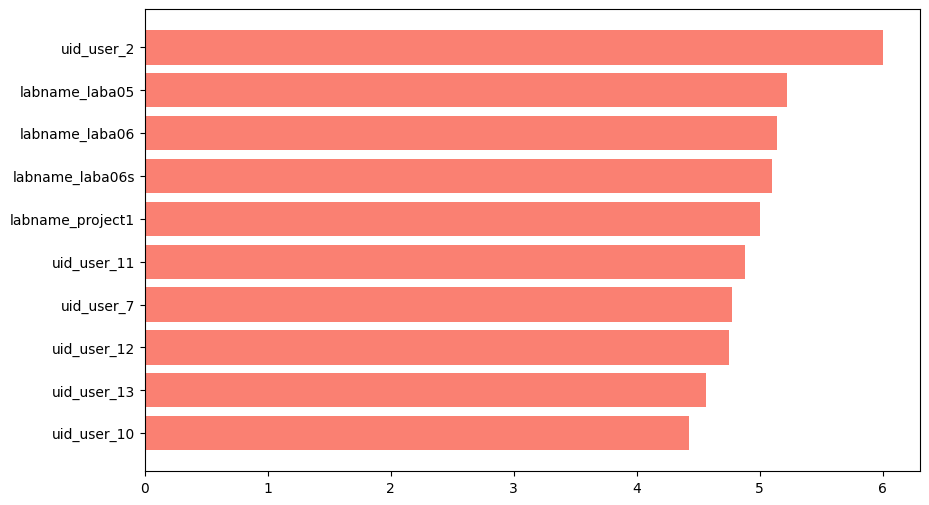

In [1511]:
plot_svc_importance(svc_linear, X.columns, n_top=10)

### c. Decision tree

1. Train a `DecisionTreeClassifier` using for the baseline model `max_depth=4`, `random_state=21`. 
2. Try different values of `max_depth`, calculate the accuracies.
3. Draw a plot (`barh`) for the baseline model with top-10 most important features (absolute value) for the trained model using the written function.

In [1512]:
dt_baseline = DecisionTreeClassifier(max_depth=4, random_state=21)
dt_baseline.fit(X, y)

acc_baseline = accuracy_score(y, dt_baseline.predict(X))
acc_baseline

0.5516014234875445

In [1513]:
for d in [2, 6, 10, 25, 50]:
    dt_tmp = DecisionTreeClassifier(max_depth=d, random_state=21)
    dt_tmp.fit(X, y)
    acc = accuracy_score(y, dt_tmp.predict(X))
    print(f"accuracy max_depth={d}: {acc}")

accuracy max_depth=2: 0.4389086595492289
accuracy max_depth=6: 0.6637010676156584
accuracy max_depth=10: 0.8196915776986952
accuracy max_depth=25: 0.9970344009489917
accuracy max_depth=50: 1.0


In [1514]:
def plot_importance(importance_values, feature_names, title, n_top=10):
    feat_importance = pd.DataFrame({'feature': feature_names, 'importance': importance_values})
    feat_importance = feat_importance.sort_values('importance', ascending=False).head(n_top)
    
    plt.figure(figsize=(10, 6))
    plt.barh(feat_importance['feature'], feat_importance['importance'], color='mediumseagreen')
    plt.gca().invert_yaxis()
    plt.title(title)
    plt.xlabel("Importance Score")
    
    plt.show()

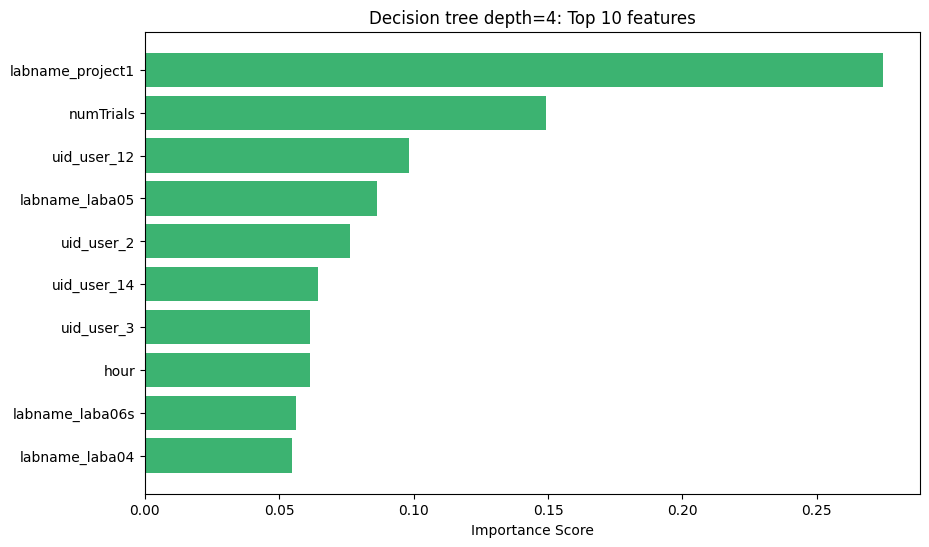

In [1515]:
plot_importance(dt_baseline.feature_importances_, 
                X.columns, 
                "Decision tree depth=4: Top 10 features")

### d. Random forest

In real life forest is a set of trees. The same thing is with machine learning. Random forest is a set of individual decision trees (check the documentation for more details).

1. Train a `RandomForestClassifier` using for the baseline model parameters `n_estimators=100`, `max_depth = 25`, `random_state=21`. 
2. Try different values of `max_depth` and `n_estimators`, calculate the accuracies.
3. Draw a plot (`barh`) for the baseline model with top-10 most important features (absolute value) for the trained model using the written function.

In [1516]:
rf_baseline = RandomForestClassifier(n_estimators=100, max_depth=25, random_state=21)
rf_baseline.fit(X, y)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",25
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap: bool, default=TrueWhether bootstrap samples are used when building trees. If False, thewhole dataset is used to build each tree.",True
,"oob_score oob_score: bool or callable, default=FalseWhether to use out-of-bag samples to estimate the generalization score.By default, :func:`~sklearn.metrics.accuracy_score` is used.Provide a callable with signature `metric(y

In [1517]:
y_pred_rf = rf_baseline.predict(X)
accuracy_score(y, y_pred_rf)

0.9988137603795967

### test with diff params

In [1518]:
params = [
    {'n': 50, 'd': 10},
    {'n': 100, 'd': 50},
    {'n': 200, 'd': 25}
]

for p in params:
    rf_tmp = RandomForestClassifier(n_estimators=p['n'], max_depth=p['d'], random_state=21)
    rf_tmp.fit(X, y)
    acc = accuracy_score(y, rf_tmp.predict(X))
    print(f"trees: {p['n']}, depth: {p['d']}, accuracy: {acc}")


trees: 50, depth: 10, accuracy: 0.8795966785290629
trees: 100, depth: 50, accuracy: 1.0
trees: 200, depth: 25, accuracy: 1.0


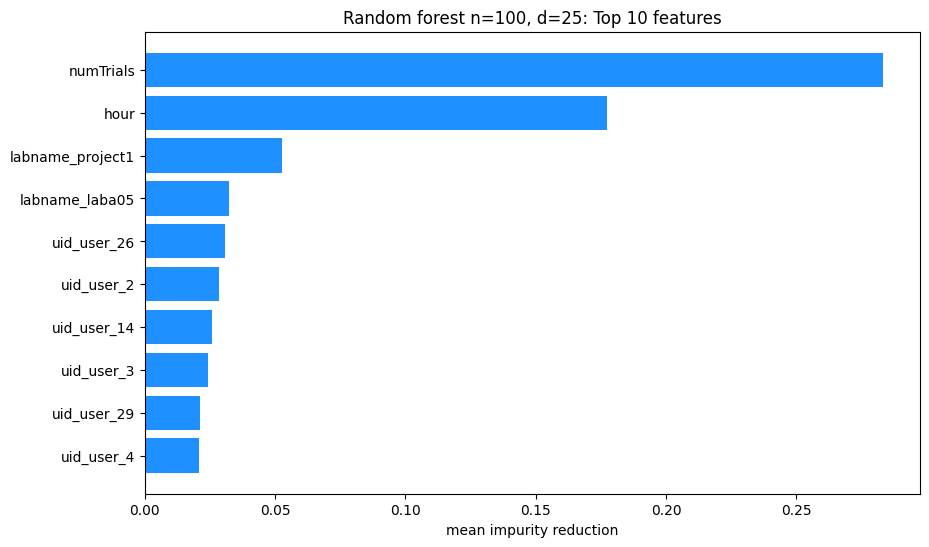

In [1519]:
def plot_rf_importance(model, feature_names, n_top=10):
    # avg importances for all trees
    importances = model.feature_importances_
    
    feat_importance = pd.DataFrame({'feature': feature_names, 'importance': importances})
    feat_importance = feat_importance.sort_values('importance', ascending=False).head(n_top)
    
    plt.figure(figsize=(10, 6))

    plt.barh(feat_importance['feature'], feat_importance['importance'], color='dodgerblue')
    plt.gca().invert_yaxis()
    plt.title(f"Random forest n=100, d=25: Top {n_top} features")
    plt.xlabel("mean impurity reduction")

    plt.show()

plot_rf_importance(rf_baseline, X.columns, n_top=10)